## Module 3: Computational Drug Discovery Project


## Project Goal:

 We (Makayla Bateman and Malcolm Epstein) are Quantitative Systems Pharmacologists at the UVA Manning Institute for Biotechnology in Fontaine Research Park working on a new weight loss drug Cavalitide. Obesity is a chronic condition associated with rapid fat accumulation that poses a health risk(1).
 
 The goal of our project is to test how Cavalitide competes with a Semiglutide weight loss drug. We will test our product with three different tasks: 

* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide and compare with the Semaglutide binding

* Task 2: Simulate the pharmacokinetics of Cavalitide treatment

* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:

According to the WHO, 940 million adults and 170 million children (aged 5-19) were obese in 2024 (1). The cause of obesity can be attributed to environmental, social, biological, or behavioral factors (1). Obesity is diagnosed using body mass index, a measure of weight relative to height, compared with the WHO reference chart (1). It is defined as a BMI greater than or equal to 30 in adults and weight greater than 2 standard deviations in children 5-19 (1). If the patient's weight isn't managed, their health can decline significantly(diabetes, heart problems, shortness of breath, etc.) as a result (2). Until the development of GLP-1 weight-loss medications, patients were treated with diet and exercise. GLP1s are more expensive, with some low-end plans costing $129 per month without insurance (3).

Obesity is much more prevalent in low-income areas than well-developed areas (4). The current cost of treatment is high, and many may not be able to afford the GLP1 medications currently on the market. Thus, a cheaper yet still effective alternative is paramount to helping these patients.

## Task 1: Fit a receptor binding model for Cavalitide: (MAKAYLA)

Our colleage identified a molecule (Cavalitide), and performed experiments to test how well it could bind to the GLP1 receptor. Now, we aim to develop a pharmacodynamics model comparing how Semaglutide and Cavalitide are able to bind and activate the GLP1 receptor. Our model was created by achieving 3 milestones:

a)	Adaptation of previous code from modeling semaglutide to fit Cavalitide binding data.


b)	Create a plot showing [Cavalitide] vs. Fraction Active Receptors (Fact) demonstrates a good fit.


c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

## Part a) Adapted Code

Adapted code for Cavalitide binding data. Changes in the original code was the name of the CSV file to load data from, labels and title on graph, and finally the addition of a comparison code to test quantitatively the difference in efficacy of the Cavalitide to Semaglutide.

In [ ]:
# Step 1: Import packages needed for Task 1
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Step 2: Create model
def Fact(L1, L2, Kd1, Kd2):
    """Fraction of active receptors with two agonists competing for one receptor.
    L1, Kd1 = GLP1 (natual ligand); L2, Kd2 = Cavalitide (drug being tested)"""
    return (Kd2*L1 + Kd1*L2)/(Kd2*Kd2 + Kd2*L1 + Kd1*L2)

# Step 3: State known parameters
Kd1 = .17                                                               # GLP1 dissociation constant [nM]
L1 = .015                                                               # Concentration of the first ligand, GLP1 after fasting [nM]
L2 = np.logspace(-3, 2 ,500)                                            # Array of 500 Cavalitide concentrations between .001 and 100 nM, smoothes model curve
# Kd2 = variable we're solving for

# Step 4: Load the data into the file

data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)     # Load data set, comma separations, skip first header row
L2_loaded, Fact_loaded = data[:,0], data[:,1]                           # Separates L2 (Cavalitide concentrations) and active fraction of drug

# Step 5: Approach 1 - brute force optimization of Kd2

Kd2_candidates = np.logspace(-3, 2, 1000)                               # 1000 candidate Kd values between .001 and 100 nM
SSE_brute = np.inf                                                      # starts best error at infinity
for Kd2_test in Kd2_candidates:
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_test))**2) # Sum of squared errors formula
    if SSE < SSE_brute:                                                 # If new SSE is lower than initial SSE, that is saved with its Kd
        SSE_brute = SSE
        Kd2_brute = Kd2_test                                            # Lowest SSE is saved into Kd2_brute
print(f"Brute-force Kd2 = {Kd2_brute:.4f} nM (SSE = {SSE_brute:.4f})")  # Prints lowest SSE Kd

# Step 6: Approach 2 - curve fit of Kd2
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),          # L2_loaded is x, Fact_loaded is y
                       L2_loaded, Fact_loaded, p0=[.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
Kd2_error = np.sqrt(pcov[0,0])                                          # Find error of measurement
SSE_fit = np.sum(Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit)**2)
print(f"Curve_fit Kd2 = {Kd2_fit:.4f} +/- {Kd2_error:.4f} nM (SSE = {SSE_fit:.4f})")

# Step 7: Compare data from Cavalitide Kd with Semaglutide Kd

Kd_semabrute = .335                                                     # Values obtained from semaglutidePK.py file Approach 1
Kd_semabrute_SSE = .0047                                                # Values obtained from semaglutidePK.py file Approach 1
Cav_vs_sema_brute = (Kd_semabrute / Kd2_fit)

Kd_semacurvefit = .350                                                  # Values obtained from semaglutidePK.py file Approach 2
Kd_semacurvefit_SSE = .0044                                             # Values obtained from semaglutidePK.py file Approach 2
Cav_vs_sema_curvefit = (Kd_semacurvefit / Kd2_fit)

Cav_vs_sema_avg = (Cav_vs_sema_brute + Cav_vs_sema_curvefit) / 2        # Take and print average of two approaches
print(f"Cavalitide binds ~{Cav_vs_sema_avg:.2f} times more tightly than semaglutide")

# Step 8: Plot data and model fits to create figure for data

plt.figure()                                                            # Create empty figure
plt.semilogx(L2_loaded, Fact_loaded, "o", c="tab:purple",
            label="Experimental data")                                  # Plots measured points with circle markers
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=4,
             label=f"Brute-Force Fit (Kd2 = {Kd2_brute:.4f} nM)")       # Plots model curve with brute-force Kd
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"Curve-Fit Fit (Kd2 = {Kd2_fit:.4f} nM)")           # Plots model curve with curve-fit Kd
plt.ylim(-.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Active Fraction")
plt.title("GLP1R Activation by Cavalitide with GLP1 Present")
plt.legend(loc="upper left")
plt.show()                                                              # Create plot with above criteria

## Part b) Plot of [Cavalitide] vs. Active Fraction

The Brute-Force Fit and Curve-Fit lines are right on top of eachother meaning they are approximately the same fits. The curve provided by these two fits are very close to the experimental data point curve. There are no major outliers shown on the graph and all points are within .05 away from the fit line. Therefore, the [Cavalitide] models demonstrate a good fit.

* At 1 nM concentration of Cavalitide, approximately 90% of GLP1 receptors are active and bound to the molecule.

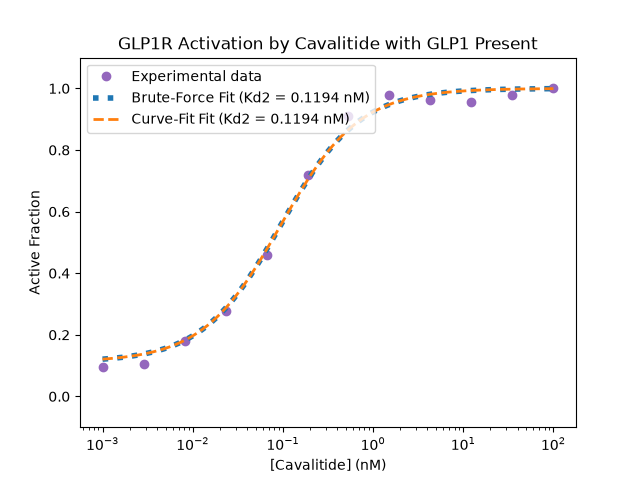

Fig.1. Plot of [Cavalitide] vs. Active Fraction (Fact)

## Part c) Interpretation of Kd value for Cavalitide

Lower Kd (dissociation constant) means there is a higher affinity for binding and the bond will be tighter between ligand and receptor. Cavalitide has a Kd of ~.1194 and Semaglutide has a Kd ~.3475. The Kd for Cavalitide is smaller than for Semaglutide meaning it will bind more tightly to the receptor and be more potent at a lower dosage. Thus, an advantage of Cavalitide vs Semaglutide is more effective weight loss potential for patients. To determine how much more tightly the Cavalitide binds than Semaglutide, I divided the brute Kd of Semaglutide by the Kd fit of Cavalitide. Then I divided the curve fit Kd of Semaglutide by the Kd fit of Cavalitide. Finally, I added the two ratios together and divided by two to find that Cavalitide binds 2.87% more tightly than Semaglutide does.

In [ ]:
Brute-force Kd2 = 0.1194 nM (SSE = 0.0073)
Curve_fit Kd2 = 0.1194 +/- 0.0038 nM (SSE = 1.1612)
Cavalitide binds ~2.87 times more tightly than semaglutide

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment (MALCOLM)

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment (MALCOLM)

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions: (MALCOLM)

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

There were two main limitations to the project: 

1. Quick turn around time


2. Only 12 data points in the data sets 


The small data set increases the chance for the data to be significantly skewed from a single outlier. If we had more time, we would find a larger data set to ensure our findings are accurate. Additionally, we would find and include Tirzepatide data and oral data as extra comparison points along with Semaglutide so the study is well rounded.

## AI Usage Statement:

We used Claude Code to help debug our code. This was helpful in ensuring our code would run smoothly and fixing minor errors relating to typos and missed punctuation formatting in our code.

## GitHub Repository Link:
https://github.com/Athena20227876/Module-_3_Repository


## References (in order):

1. World Health Organization: WHO. (2026, October 7). Obesity and overweight. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight

2. HexaHealth. (2023, October 12). Obesity symptoms - Understand the common signs here. HexaHealth. https://www.hexahealth.com/blog/symptoms-of-obesity

3. Anthony. (2026, October 8). Cheapest GLP-1 without insurance (2026): Most affordable options ranked. CheckWeightLoss. https://checkweightloss.com/cheapest-glp1/

4. Petrov, N. (2026, July 20). Obesity and Poverty statistics. https://worldmetrics.org/obesity-and-poverty-statistics/

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*